<a href="https://colab.research.google.com/github/mfaridzmaulana/KLASIFIKASI-CITRA-DENGAN-CNN/blob/main/notebooks/08_uji_kondisi_ideal_sulit_MFM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# ==========================================
# NOTEBOOK 08
# PENGUJIAN KONDISI IDEAL VS SULIT
# KELOMPOK 3
# ==========================================

import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from google.colab import drive
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

drive.mount('/content/drive')

DATASET_DIR = "/content/drive/.shortcut-targets-by-id/1LoCHPgLL2xzbYllXiCpFE89B8TmW7Efs/COMPUTER VISION_TI 2026/kelompok 3/KLASIFIKASI CITRA DENGAN CNN/DATA MENTAH"

OUTPUT_DIR = os.path.dirname(DATASET_DIR)

# Memuat dataset split yang sudah digunakan
data = np.load(
    os.path.join(OUTPUT_DIR, "dataset_split.npz")
)

X_test = data["X_test"]
y_test = data["y_test"]
k_test = data["k_test"]

nama_kelas = ["TAS", "BUKU GAMBAR", "LAPTOP"]

# Memuat model Improved
MODEL_FILE = os.path.join(
    OUTPUT_DIR,
    "model_cnn_improved.keras"
)

model_improved = tf.keras.models.load_model(MODEL_FILE)

# Prediksi
y_true = (
    np.argmax(y_test, axis=1)
    if len(y_test.shape) > 1
    else y_test.astype(int)
)

y_probability = model_improved.predict(X_test, verbose=0)
y_pred = np.argmax(y_probability, axis=1)

print("NOTEBOOK 08 SIAP")
print("Jumlah testing:", len(X_test))
print("Distribusi kondisi:", np.unique(k_test, return_counts=True))


Mounted at /content/drive
NOTEBOOK 08 SIAP
Jumlah testing: 18
Distribusi kondisi: (array(['KONDISI IDEAL', 'KONDISI SULIT'], dtype='<U13'), array([9, 9]))


In [2]:

# ==========================================
# AUDIT DISTRIBUSI KELAS IDEAL VS SULIT
# ==========================================

print("ISI FILE DATASET:")
print(data.files)

for kondisi in ["KONDISI IDEAL", "KONDISI SULIT"]:

    indeks = np.where(k_test == kondisi)[0]

    print("\n", "=" * 50)
    print(kondisi)
    print("=" * 50)

    for kelas_id, kelas in enumerate(nama_kelas):

        indeks_kelas = [
            idx for idx in indeks
            if y_true[idx] == kelas_id
        ]

        benar = sum(
            y_pred[idx] == y_true[idx]
            for idx in indeks_kelas
        )

        salah = len(indeks_kelas) - benar

        print(
            f"{kelas}: {len(indeks_kelas)} gambar | "
            f"Benar: {benar} | Salah: {salah}"
        )


ISI FILE DATASET:
['X_train', 'X_val', 'X_test', 'y_train', 'y_val', 'y_test', 'k_train', 'k_val', 'k_test']

KONDISI IDEAL
TAS: 3 gambar | Benar: 2 | Salah: 1
BUKU GAMBAR: 3 gambar | Benar: 2 | Salah: 1
LAPTOP: 3 gambar | Benar: 0 | Salah: 3

KONDISI SULIT
TAS: 3 gambar | Benar: 2 | Salah: 1
BUKU GAMBAR: 3 gambar | Benar: 3 | Salah: 0
LAPTOP: 3 gambar | Benar: 0 | Salah: 3


ConfusionMatrixDisplay berhasil diimpor!

KONDISI IDEAL
Accuracy: 44.44%

Classification Report:
              precision    recall  f1-score   support

         TAS       0.40      0.67      0.50         3
 BUKU GAMBAR       0.50      0.67      0.57         3
      LAPTOP       0.00      0.00      0.00         3

    accuracy                           0.44         9
   macro avg       0.30      0.44      0.36         9
weighted avg       0.30      0.44      0.36         9

Confusion Matrix:
[[2 1 0]
 [1 2 0]
 [2 1 0]]


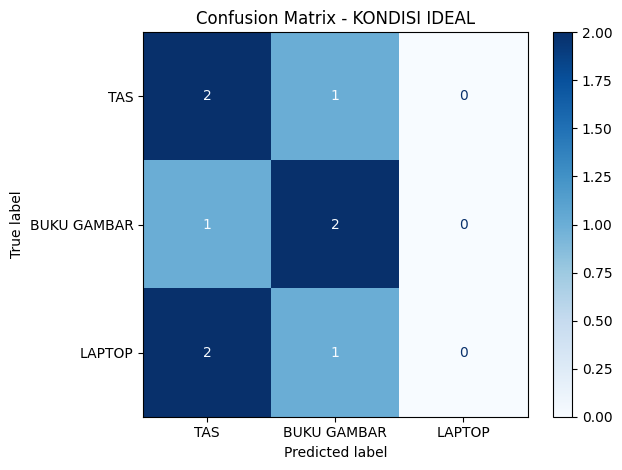


KONDISI SULIT
Accuracy: 55.56%

Classification Report:
              precision    recall  f1-score   support

         TAS       0.50      0.67      0.57         3
 BUKU GAMBAR       0.60      1.00      0.75         3
      LAPTOP       0.00      0.00      0.00         3

    accuracy                           0.56         9
   macro avg       0.37      0.56      0.44         9
weighted avg       0.37      0.56      0.44         9

Confusion Matrix:
[[2 1 0]
 [0 3 0]
 [2 1 0]]


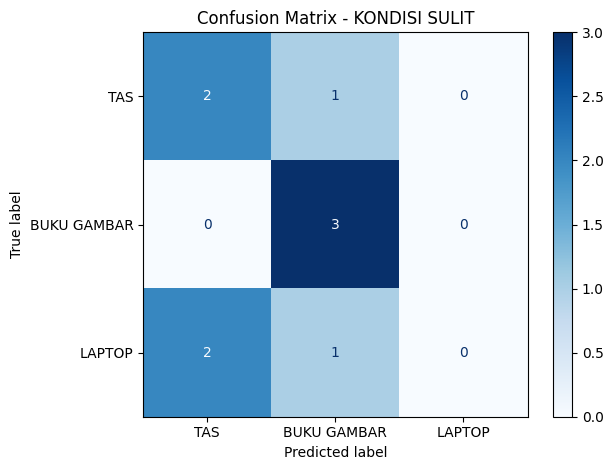

In [7]:

# ==========================================
# 4. EVALUASI LENGKAP IDEAL VS SULIT
# ==========================================

from sklearn.metrics import ConfusionMatrixDisplay

print("ConfusionMatrixDisplay berhasil diimpor!")

hasil_kondisi = {}

for kondisi in ["KONDISI IDEAL", "KONDISI SULIT"]:

    indeks = np.where(k_test == kondisi)[0]

    y_asli = y_true[indeks]
    y_hasil = y_pred[indeks]

    akurasi = accuracy_score(y_asli, y_hasil)

    cm = confusion_matrix(
        y_asli,
        y_hasil,
        labels=[0, 1, 2]
    )

    hasil_kondisi[kondisi] = {
        "accuracy": akurasi,
        "confusion_matrix": cm,
        "y_true": y_asli,
        "y_pred": y_hasil
    }

    print("\n" + "=" * 55)
    print(kondisi)
    print("=" * 55)

    print(f"Accuracy: {akurasi * 100:.2f}%")

    print("\nClassification Report:")

    print(classification_report(
        y_asli,
        y_hasil,
        labels=[0, 1, 2],
        target_names=nama_kelas,
        zero_division=0
    ))

    print("Confusion Matrix:")
    print(cm)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=nama_kelas
    )

    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"Confusion Matrix - {kondisi}")
    plt.tight_layout()
    plt.show()


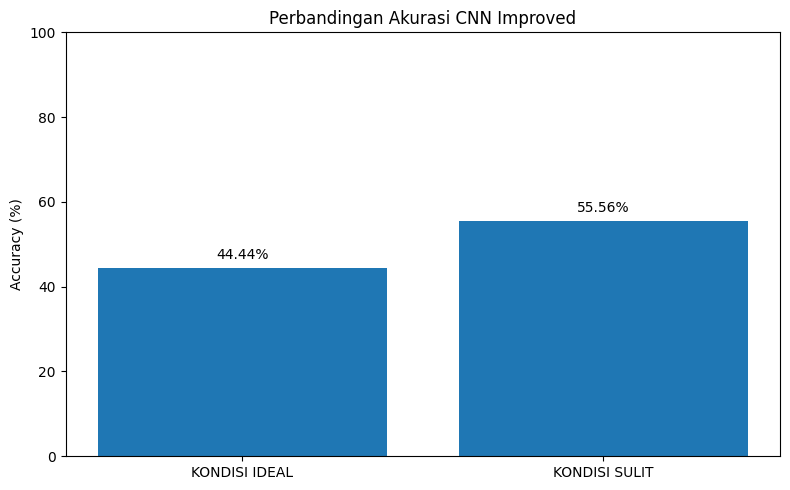

In [8]:

# ==========================================
# 5. GRAFIK PERBANDINGAN IDEAL VS SULIT
# ==========================================

akurasi_ideal = (
    hasil_kondisi["KONDISI IDEAL"]["accuracy"] * 100
)

akurasi_sulit = (
    hasil_kondisi["KONDISI SULIT"]["accuracy"] * 100
)

plt.figure(figsize=(8, 5))

bars = plt.bar(
    ["KONDISI IDEAL", "KONDISI SULIT"],
    [akurasi_ideal, akurasi_sulit]
)

plt.title("Perbandingan Akurasi CNN Improved")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

for bar in bars:
    nilai = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        nilai + 2,
        f"{nilai:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()



HASIL KONDISI IDEAL
Akurasi: 44.44%

Classification Report:
              precision    recall  f1-score   support

         TAS       0.40      0.67      0.50         3
 BUKU GAMBAR       0.50      0.67      0.57         3
      LAPTOP       0.00      0.00      0.00         3

    accuracy                           0.44         9
   macro avg       0.30      0.44      0.36         9
weighted avg       0.30      0.44      0.36         9

Confusion Matrix:
[[2 1 0]
 [1 2 0]
 [2 1 0]]


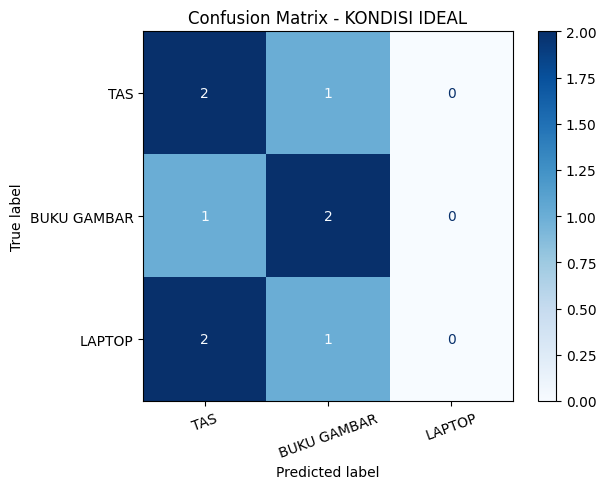


HASIL KONDISI SULIT
Akurasi: 55.56%

Classification Report:
              precision    recall  f1-score   support

         TAS       0.50      0.67      0.57         3
 BUKU GAMBAR       0.60      1.00      0.75         3
      LAPTOP       0.00      0.00      0.00         3

    accuracy                           0.56         9
   macro avg       0.37      0.56      0.44         9
weighted avg       0.37      0.56      0.44         9

Confusion Matrix:
[[2 1 0]
 [0 3 0]
 [2 1 0]]


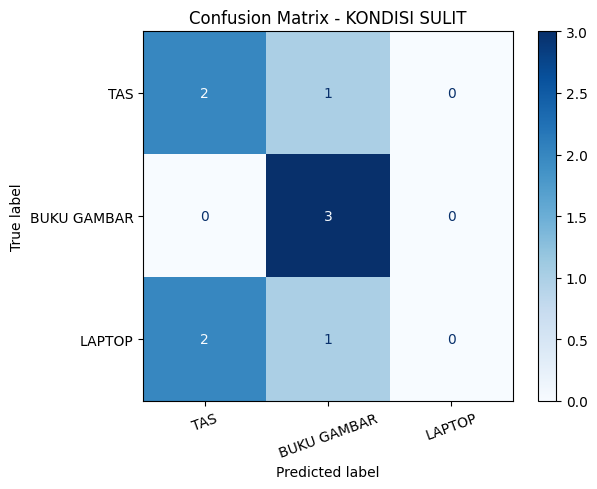

In [9]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import numpy as np
import matplotlib.pyplot as plt

hasil_kondisi = {}

for kondisi in ["KONDISI IDEAL", "KONDISI SULIT"]:

    indeks = np.where(k_test == kondisi)[0]

    y_asli = y_true[indeks]
    y_hasil = y_pred[indeks]

    akurasi = accuracy_score(y_asli, y_hasil)

    cm = confusion_matrix(
        y_asli,
        y_hasil,
        labels=[0, 1, 2]
    )

    hasil_kondisi[kondisi] = {
        "accuracy": akurasi,
        "confusion_matrix": cm,
        "y_true": y_asli,
        "y_pred": y_hasil
    }

    print("\n================================")
    print("HASIL", kondisi)
    print("================================")

    print(f"Akurasi: {akurasi * 100:.2f}%")

    print("\nClassification Report:")
    print(classification_report(
        y_asli,
        y_hasil,
        labels=[0, 1, 2],
        target_names=nama_kelas,
        zero_division=0
    ))

    print("Confusion Matrix:")
    print(cm)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=nama_kelas
    )

    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"Confusion Matrix - {kondisi}")
    plt.xticks(rotation=20)
    plt.show()

ANALISIS KESALAHAN PREDIKSI CNN IMPROVED

Kesalahan ke-1
Label Asli : LAPTOP
Prediksi   : TAS
Kondisi    : KONDISI SULIT
Probabilitas:
TAS: 34.73%
BUKU GAMBAR: 34.66%
LAPTOP: 30.60%


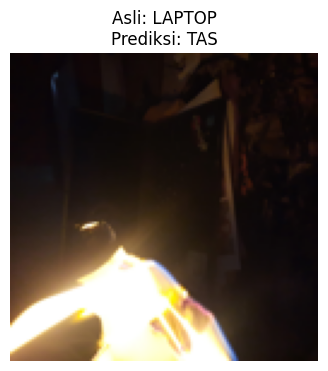


Kesalahan ke-2
Label Asli : BUKU GAMBAR
Prediksi   : TAS
Kondisi    : KONDISI IDEAL
Probabilitas:
TAS: 37.00%
BUKU GAMBAR: 34.54%
LAPTOP: 28.46%


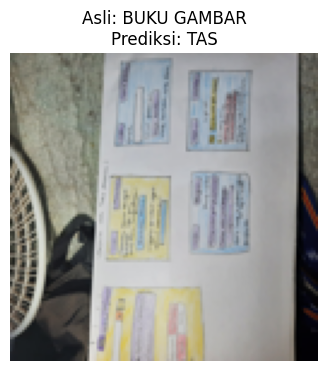


Kesalahan ke-3
Label Asli : TAS
Prediksi   : BUKU GAMBAR
Kondisi    : KONDISI IDEAL
Probabilitas:
TAS: 34.15%
BUKU GAMBAR: 35.94%
LAPTOP: 29.92%


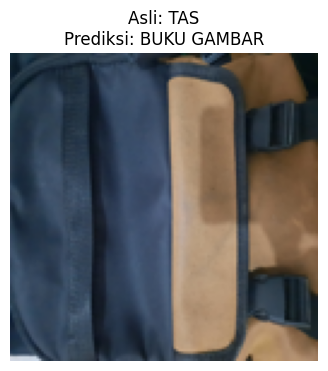


Kesalahan ke-4
Label Asli : LAPTOP
Prediksi   : TAS
Kondisi    : KONDISI IDEAL
Probabilitas:
TAS: 35.82%
BUKU GAMBAR: 34.40%
LAPTOP: 29.78%


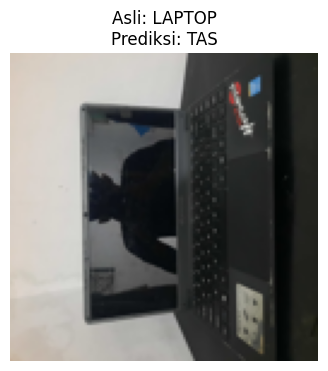


Kesalahan ke-5
Label Asli : LAPTOP
Prediksi   : TAS
Kondisi    : KONDISI SULIT
Probabilitas:
TAS: 35.28%
BUKU GAMBAR: 34.91%
LAPTOP: 29.81%


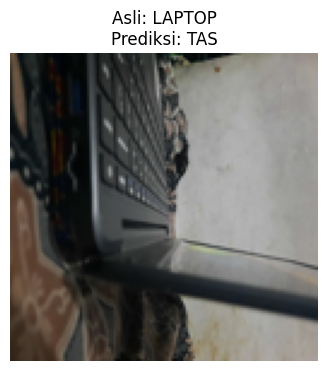


Kesalahan ke-6
Label Asli : LAPTOP
Prediksi   : BUKU GAMBAR
Kondisi    : KONDISI SULIT
Probabilitas:
TAS: 33.53%
BUKU GAMBAR: 37.59%
LAPTOP: 28.88%


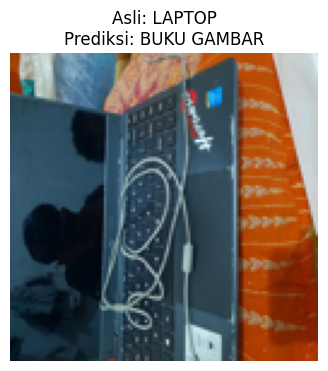


Kesalahan ke-7
Label Asli : LAPTOP
Prediksi   : BUKU GAMBAR
Kondisi    : KONDISI IDEAL
Probabilitas:
TAS: 35.44%
BUKU GAMBAR: 35.82%
LAPTOP: 28.73%


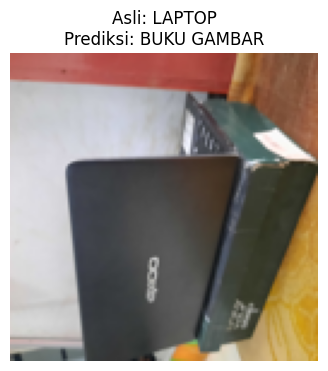


Kesalahan ke-8
Label Asli : LAPTOP
Prediksi   : TAS
Kondisi    : KONDISI IDEAL
Probabilitas:
TAS: 37.21%
BUKU GAMBAR: 34.27%
LAPTOP: 28.52%


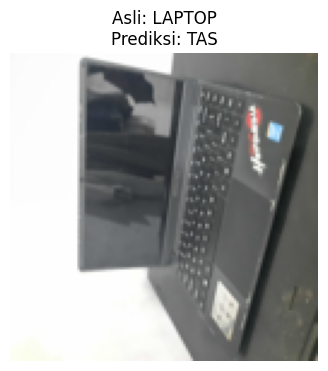


Kesalahan ke-9
Label Asli : TAS
Prediksi   : BUKU GAMBAR
Kondisi    : KONDISI SULIT
Probabilitas:
TAS: 35.09%
BUKU GAMBAR: 35.73%
LAPTOP: 29.18%


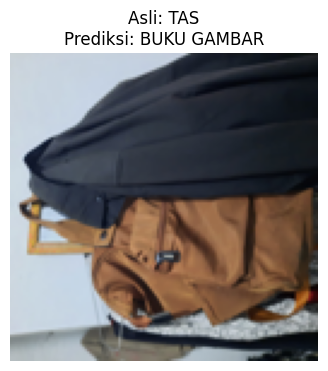


TOTAL GAMBAR SALAH: 9


In [11]:
# ==========================================
# 6. ANALISIS KESALAHAN PREDIKSI
# CNN IMPROVED
# ==========================================

print("ANALISIS KESALAHAN PREDIKSI CNN IMPROVED")

nama_kondisi = k_test

jumlah_salah = 0

for i in range(len(y_true)):

    if y_true[i] != y_pred[i]:

        jumlah_salah += 1

        print("\n===================================")
        print(f"Kesalahan ke-{jumlah_salah}")
        print("===================================")

        print("Label Asli :", nama_kelas[y_true[i]])
        print("Prediksi   :", nama_kelas[y_pred[i]])
        print("Kondisi    :", nama_kondisi[i])

        print("Probabilitas:")
        for j, kelas in enumerate(nama_kelas):
            print(
                f"{kelas}: "
                f"{y_probability[i][j] * 100:.2f}%"
            )

        plt.figure(figsize=(4, 4))

        plt.imshow(X_test[i])
        plt.title(
            f"Asli: {nama_kelas[y_true[i]]}\n"
            f"Prediksi: {nama_kelas[y_pred[i]]}"
        )

        plt.axis("off")
        plt.show()

print("\n===================================")
print("TOTAL GAMBAR SALAH:", jumlah_salah)
print("===================================")

In [13]:
# ==========================================
# 7. RINGKASAN KESALAHAN PREDIKSI
# ==========================================

import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score

ringkasan = []

for i, kelas in enumerate(nama_kelas):

    salah = np.sum(
        (y_true == i) & (y_pred != i)
    )

    total = np.sum(y_true == i)
    benar = total - salah

    ringkasan.append({
        "Kelas": kelas,
        "Total Data": total,
        "Prediksi Benar": benar,
        "Prediksi Salah": salah,
        "Akurasi (%)": round(
            benar / total * 100, 2
        ) if total > 0 else 0
    })

df_ringkasan = pd.DataFrame(ringkasan)

display(df_ringkasan)

print("Total testing:", len(y_true))
print("Total salah:", np.sum(y_true != y_pred))
print("Akurasi:", f"{accuracy_score(y_true, y_pred)*100:.2f}%")

,Kelas,Total Data,Prediksi Benar,Prediksi Salah,Akurasi (%)
0,TAS,6,4,2,66.67
1,BUKU GAMBAR,6,5,1,83.33
2,LAPTOP,6,0,6,0.00


Total testing: 18
Total salah: 9
Akurasi: 50.00%


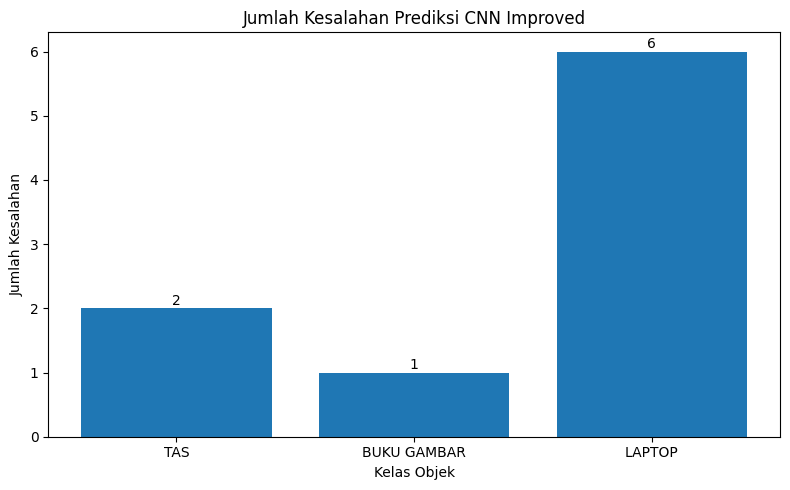

In [14]:
# ==========================================
# 8. GRAFIK KESALAHAN SETIAP KELAS
# ==========================================

plt.figure(figsize=(8, 5))

bars = plt.bar(
    df_ringkasan["Kelas"],
    df_ringkasan["Prediksi Salah"]
)

plt.title("Jumlah Kesalahan Prediksi CNN Improved")
plt.xlabel("Kelas Objek")
plt.ylabel("Jumlah Kesalahan")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.05,
        str(int(bar.get_height())),
        ha="center"
    )

plt.tight_layout()
plt.show()

# New Section